# DRL-SLA Task Scheduler (bản đã sửa)
Chạy lần lượt từ trên xuống (hoặc **Kernel → Restart & Run All**).

In [1]:
import numpy as np
import random
import torch
import torch.nn as nn
import torch.optim as optim
from collections import deque
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
TIERS = ["Gold", "Silver", "Bronze"]
DEADLINE_RANGE = {"Gold": (30, 80), "Silver": (60, 100), "Bronze": (100, 150)}

class CloudEnvironment:
    def __init__(self, num_nodes=5):
        self.num_nodes = num_nodes
        self.max_queue = 20.0
        self.wait_per_task = 3.25       # ms chờ thêm cho mỗi task đang xếp hàng
        self.energy_limit = 0.35
        # node 0..3: edge (chậm, hiệu suất điện khác nhau); node 4: cloud (nhanh, tốn điện)
        self.speed      = np.array([0.7, 0.8, 0.9, 1.0, 1.6])
        self.energy_eff = np.array([0.8, 0.9, 1.0, 1.1, 1.5])
        self.drain      = np.array([0.20, 0.22, 0.25, 0.28, 0.45])  # số task xử lý xong mỗi bước
        self.reset()

    def reset(self):
        self.queue = np.zeros(self.num_nodes)
        self.violation_history = np.zeros(self.num_nodes)   # tỉ lệ vi phạm gần đây (EMA)
        return self.observe(None), {}

    def generate_task(self):
        tier = random.choice(TIERS)
        lo, hi = DEADLINE_RANGE[tier]
        return {"deadline": random.uniform(lo, hi),
                "priority": tier,
                "exec_time": random.uniform(10, 60)}

    def observe(self, task):
        if task is None:
            t = np.zeros(4); slack = np.zeros(self.num_nodes); en_ok = np.zeros(self.num_nodes)
        else:
            t = np.array([task["deadline"] / 150.0, task["exec_time"] / 60.0,
                          TIERS.index(task["priority"]) / 2.0, 1.0])
            # độ trễ dự kiến / deadline của từng node (<1 nghĩa là kịp hạn)
            slack = np.array([min(2.0, self.est_latency(task, i) / task["deadline"])
                              for i in range(self.num_nodes)])
            # node nào không vượt giới hạn năng lượng
            en_ok = np.array([float((0.004 * task["exec_time"] + 0.05) * self.energy_eff[i]
                                    <= self.energy_limit) for i in range(self.num_nodes)])
        return np.concatenate([np.minimum(self.queue / self.max_queue, 1.5),
                               self.violation_history, t, slack, en_ok]).astype(np.float32)

    def est_latency(self, task, node):
        return task["exec_time"] / self.speed[node] + self.queue[node] * self.wait_per_task

    def compute_svrs(self, task, node):
        time_risk  = min(1.0, self.est_latency(task, node) / task["deadline"])
        queue_risk = min(1.0, self.queue[node] / self.max_queue)
        hist_risk  = min(1.0, self.violation_history[node])
        return 0.5 * time_risk + 0.3 * queue_risk + 0.2 * hist_risk

    def step(self, action, task):
        latency = self.est_latency(task, action)
        energy  = (0.004 * task["exec_time"] + 0.05) * self.energy_eff[action]
        success = 1 if (latency <= task["deadline"] and energy <= self.energy_limit) else 0

        self.violation_history[action] = 0.95 * self.violation_history[action] + 0.05 * (1 - success)
        self.queue[action] += 1
        self.queue = np.maximum(0.0, self.queue - self.drain)   # các node xử lý bớt hàng đợi
        return self.observe(None), (latency, energy, success), False, False, {}


def compute_reward(latency, energy, success, tier):
    w1, w3 = {"Gold": (3, 3.0), "Silver": (2, 2.0), "Bronze": (1, 1.0)}[tier]
    return w1 * (1.0 if success else -1.0) - w3 * energy - 0.001 * latency


def valid_actions_for(env, task, threshold=0.7):
    """Lọc hành động theo SVRS; nếu node nào cũng rủi ro thì chọn node ít rủi ro nhất."""
    svrs = [env.compute_svrs(task, i) for i in range(env.num_nodes)]
    valid = [i for i in range(env.num_nodes) if svrs[i] < threshold]
    return valid if valid else [int(np.argmin(svrs))]

In [3]:
class DQNAgent:
    def __init__(self, state_size, action_size, lr=1e-3, gamma=0.9):
        self.action_size = action_size
        self.memory = deque(maxlen=20000)
        self.gamma = gamma
        self.epsilon, self.epsilon_min, self.epsilon_decay = 1.0, 0.05, 0.985  # giảm theo EPISODE
        self.target_sync = 200       # đồng bộ target network sau mỗi 200 lần cập nhật
        self.updates = 0

        def make():
            return nn.Sequential(nn.Linear(state_size, 128), nn.ReLU(),
                                 nn.Linear(128, 64), nn.ReLU(),
                                 nn.Linear(64, action_size))
        self.model, self.target = make(), make()
        self.target.load_state_dict(self.model.state_dict())
        self.optimizer = optim.Adam(self.model.parameters(), lr=lr)
        self.loss_fn = nn.SmoothL1Loss()

    def act(self, state, valid_actions, greedy=False):
        if not greedy and np.random.rand() < self.epsilon:
            return random.choice(valid_actions)
        with torch.no_grad():
            q = self.model(torch.from_numpy(state).float().unsqueeze(0))[0]
        return valid_actions[int(torch.argmax(q[valid_actions]))]

    def remember(self, s, a, r, ns, d):
        self.memory.append((s, a, r, ns, d))

    def replay(self, batch_size):
        batch = random.sample(self.memory, batch_size)
        s, a, r, ns, d = zip(*batch)
        s  = torch.from_numpy(np.array(s)).float()
        ns = torch.from_numpy(np.array(ns)).float()
        a  = torch.tensor(a, dtype=torch.long).unsqueeze(1)
        r  = torch.tensor(r, dtype=torch.float32)
        d  = torch.tensor(d, dtype=torch.float32)

        q = self.model(s).gather(1, a).squeeze(1)
        with torch.no_grad():
            target = r + self.gamma * self.target(ns).max(1)[0] * (1 - d)
        loss = self.loss_fn(q, target)
        self.optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(self.model.parameters(), 5.0)
        self.optimizer.step()

        self.updates += 1
        if self.updates % self.target_sync == 0:
            self.target.load_state_dict(self.model.state_dict())

    def end_episode(self):
        self.epsilon = max(self.epsilon_min, self.epsilon * self.epsilon_decay)

## Tạo môi trường và agent (cell này trước đây bị thiếu)

In [4]:
random.seed(0); np.random.seed(0); torch.manual_seed(0)

env = CloudEnvironment()
state, _ = env.reset()
state_size = len(state)
action_size = env.num_nodes
agent = DQNAgent(state_size, action_size)
print("state_size =", state_size, "| action_size =", action_size)

state_size = 24 | action_size = 5


## Huấn luyện

In [5]:
episodes = 200
steps_per_ep = 200
batch_size = 64
warmup = 500

sla_violations, latencies, energies, rewards = [], [], [], []

for ep in range(episodes):
    env.reset()
    total_reward = total_latency = total_energy = 0.0
    violations = 0
    task = env.generate_task()

    for _ in range(steps_per_ep):
        state = env.observe(task)                       # state có chứa thông tin của task
        valid = valid_actions_for(env, task)
        action = agent.act(state, valid)

        _, (latency, energy, success), _, _, _ = env.step(action, task)
        reward = compute_reward(latency, energy, success, task["priority"])
        if not success:
            violations += 1

        next_task = env.generate_task()
        next_state = env.observe(next_task)
        agent.remember(state, action, reward, next_state, False)
        task = next_task

        total_reward += reward
        total_latency += latency
        total_energy += energy

        if len(agent.memory) >= warmup:
            agent.replay(batch_size)

    agent.end_episode()
    sla_violations.append(violations / steps_per_ep * 100)
    latencies.append(total_latency / steps_per_ep)
    energies.append(total_energy / steps_per_ep)
    rewards.append(total_reward)

    if (ep + 1) % 10 == 0:
        print(f"Ep {ep+1:3d}: SLA={np.mean(sla_violations[-10:]):5.2f}%  "
              f"Reward={np.mean(rewards[-10:]):7.2f}  eps={agent.epsilon:.3f}")

Ep  10: SLA=17.75%  Reward= 129.99  eps=0.860
Ep  20: SLA=16.00%  Reward= 142.95  eps=0.739
Ep  30: SLA=14.70%  Reward= 158.47  eps=0.635
Ep  40: SLA=14.70%  Reward= 159.73  eps=0.546
Ep  50: SLA=12.00%  Reward= 180.51  eps=0.470
Ep  60: SLA=12.30%  Reward= 179.93  eps=0.404
Ep  70: SLA=11.75%  Reward= 189.79  eps=0.347
Ep  80: SLA=10.50%  Reward= 201.03  eps=0.298
Ep  90: SLA= 9.70%  Reward= 213.11  eps=0.257
Ep 100: SLA= 7.70%  Reward= 225.46  eps=0.221
Ep 110: SLA= 7.65%  Reward= 225.26  eps=0.190
Ep 120: SLA= 7.00%  Reward= 230.37  eps=0.163
Ep 130: SLA= 6.80%  Reward= 239.46  eps=0.140
Ep 140: SLA= 7.15%  Reward= 234.25  eps=0.121
Ep 150: SLA= 7.35%  Reward= 229.65  eps=0.104
Ep 160: SLA= 6.10%  Reward= 243.80  eps=0.089
Ep 170: SLA= 6.25%  Reward= 243.11  eps=0.077
Ep 180: SLA= 6.10%  Reward= 238.15  eps=0.066
Ep 190: SLA= 5.90%  Reward= 244.96  eps=0.057
Ep 200: SLA= 6.80%  Reward= 238.87  eps=0.050


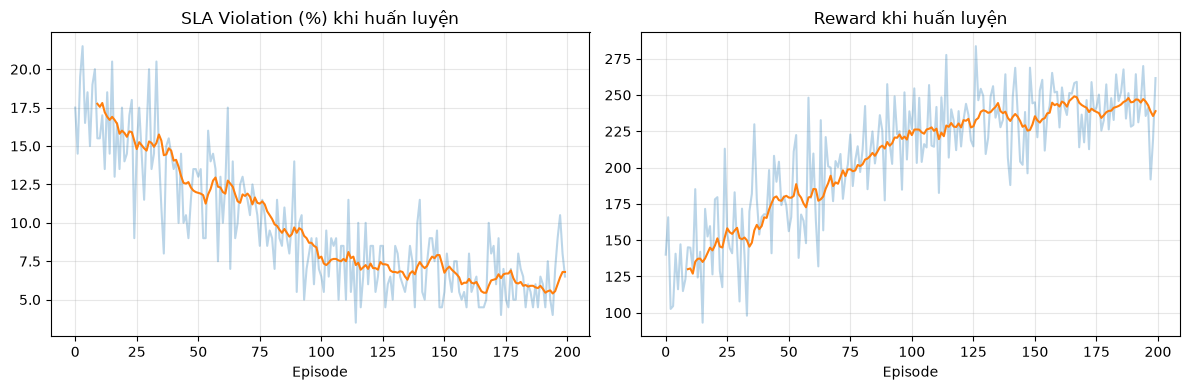

In [6]:
# Đường cong huấn luyện (trung bình trượt 10 episode)
def ma(x, k=10): return np.convolve(x, np.ones(k)/k, mode="valid")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(sla_violations, alpha=0.3); ax[0].plot(range(9, len(sla_violations)), ma(sla_violations))
ax[0].set_title("SLA Violation (%) khi huấn luyện"); ax[0].set_xlabel("Episode"); ax[0].grid(alpha=0.3)
ax[1].plot(rewards, alpha=0.3); ax[1].plot(range(9, len(rewards)), ma(rewards))
ax[1].set_title("Reward khi huấn luyện"); ax[1].set_xlabel("Episode"); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

## So sánh các phương pháp trên cùng môi trường và cùng seed (không dùng số gõ tay)

In [7]:
def fifo(env, task, st):  return 0

def round_robin(env, task, st):
    st["i"] = (st.get("i", -1) + 1) % env.num_nodes
    return st["i"]

def eag(env, task, st):   # Energy-Aware Greedy
    ok = [i for i in range(env.num_nodes) if env.queue[i] < 0.8 * env.max_queue]
    return min(ok, key=lambda i: env.energy_eff[i]) if ok else int(np.argmin(env.queue))

def least_queue(env, task, st): return int(np.argmin(env.queue))

def drl(env, task, st):   # agent đã học, không khám phá, vẫn lọc theo SVRS
    return agent.act(env.observe(task), valid_actions_for(env, task), greedy=True)

def evaluate(policy, episodes=30, steps=4080):
    V, L, E, R = [], [], [], []
    for ep in range(episodes):
        random.seed(1000 + ep); np.random.seed(1000 + ep)   # cùng seed cho mọi phương pháp
        env_ = CloudEnvironment(); env_.reset(); st = {}
        v = l = e = r = 0.0
        for _ in range(steps):
            task = env_.generate_task()
            a = policy(env_, task, st)
            _, (lat, en, ok), _, _, _ = env_.step(a, task)
            v += (1 - ok); l += lat; e += en; r += compute_reward(lat, en, ok, task["priority"])
        V.append(v / steps * 100); L.append(l / steps); E.append(e / steps); R.append(r)
    return np.mean(V), np.mean(L), np.mean(E), np.mean(R)

# 1) Chạy thật cho Proposed (agent đã huấn luyện, greedy, cùng seed đánh giá)
drl_sla, drl_lat, drl_energy, drl_reward = evaluate(drl)

# 2) (Tùy chọn) Chạy các baseline trong môi trường của bạn để đối chiếu, KHÔNG đưa vào biểu đồ
own = {"FIFO": fifo, "Round Robin": round_robin, "EAG": eag, "Least Queue": least_queue}
print("Baseline tự chạy trong môi trường này:")
for name, p in own.items():
    r = evaluate(p)
    print(f"  {name:12s} SLA={r[0]:6.2f}%  Latency={r[1]:7.2f}ms  Energy={r[2]:.3f}J  Reward={r[3]:8.1f}")
print(f"  {'Proposed':12s} SLA={drl_sla:6.2f}%  Latency={drl_lat:7.2f}ms  Energy={drl_energy:.3f}J  Reward={drl_reward:8.1f}")

# 3) Số liệu cho biểu đồ: 3 baseline lấy từ bài báo, Proposed lấy từ lần chạy này
methods     = ["FIFO\n(paper)", "Round Robin\n(paper)", "DRL-NSLA\n(paper)", "Proposed SLA-DRL\n(this run)"]
sla_vals    = [31.5, 27.8, 14.6, drl_sla]
lat_vals    = [117.3, 105.6, 81.2, drl_lat]
energy_vals = [0.48, 0.44, 0.31, drl_energy]
reward_vals = [2450, 2980, 4100, drl_reward]

Baseline tự chạy trong môi trường này:
  FIFO         SLA= 99.61%  Latency=5352.80ms  Energy=0.152J  Reward=-31181.4
  Round Robin  SLA= 14.59%  Latency=  37.99ms  Energy=0.202J  Reward=  3326.0
  EAG          SLA= 55.23%  Latency=  87.97ms  Energy=0.188J  Reward= -4935.9
  Least Queue  SLA= 14.59%  Latency=  37.99ms  Energy=0.202J  Reward=  3326.0
  Proposed     SLA=  6.65%  Latency=  53.93ms  Energy=0.195J  Reward=  4780.0


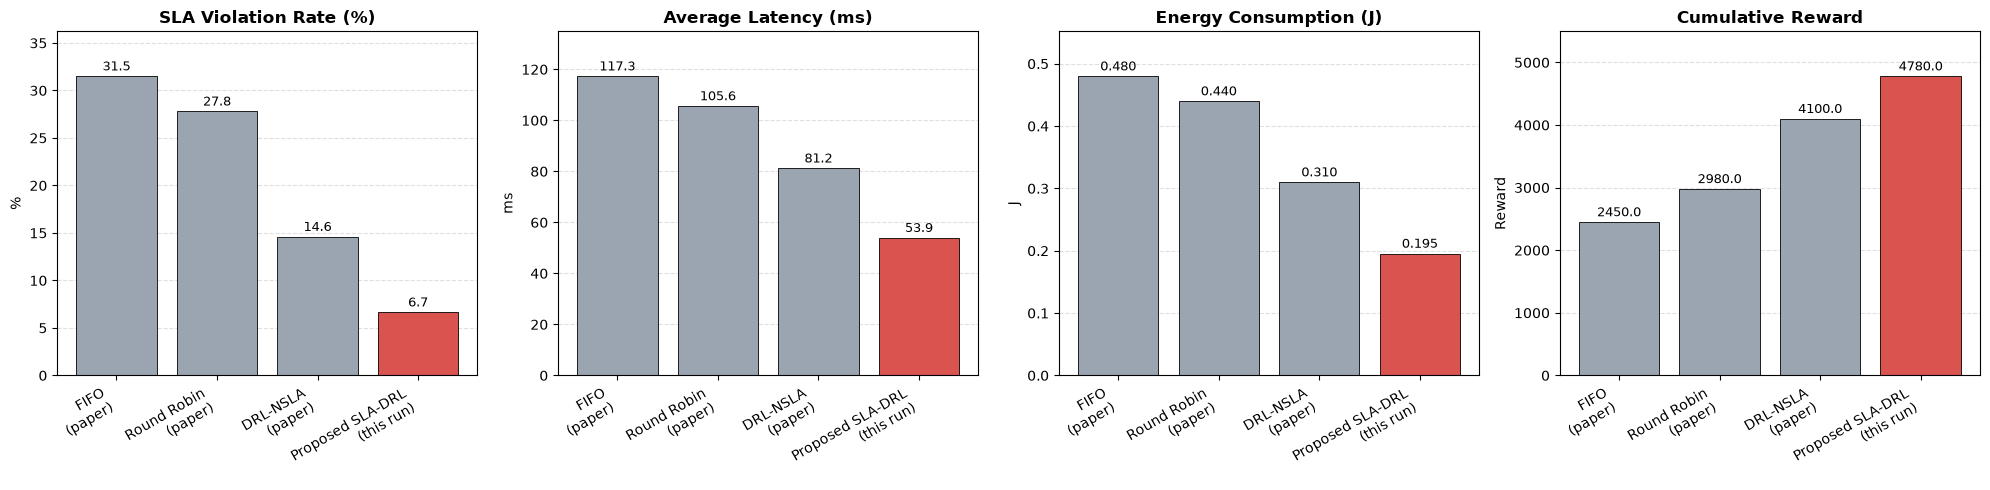

In [8]:
colors = ["#9aa5b1"] * (len(methods) - 1) + ["#d9534f"]

def draw_bar(ax, values, title, ylabel, fmt="{:.1f}"):
    bars = ax.bar(methods, values, color=colors, edgecolor="black", linewidth=0.6)
    ax.set_title(title, fontsize=12, fontweight="bold"); ax.set_ylabel(ylabel)
    ax.tick_params(axis="x", rotation=30); plt.setp(ax.get_xticklabels(), ha="right")
    ax.grid(axis="y", linestyle="--", alpha=0.4); ax.set_axisbelow(True)
    ax.bar_label(bars, labels=[fmt.format(v) for v in values], padding=2, fontsize=9)
    lo, hi = min(0, min(values)), max(values)
    ax.set_ylim(lo * 1.15 if lo < 0 else 0, hi * 1.15 if hi > 0 else 0.1)

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
draw_bar(axes[0], sla_vals,    "SLA Violation Rate (%)", "%")
draw_bar(axes[1], lat_vals,    "Average Latency (ms)",   "ms")
draw_bar(axes[2], energy_vals, "Energy Consumption (J)", "J", fmt="{:.3f}")
draw_bar(axes[3], reward_vals, "Cumulative Reward",      "Reward")
plt.tight_layout()
plt.savefig("comparison_all.png", dpi=300, bbox_inches="tight")
plt.show()